<span style="font-size:2em;">Instructor: Dr. Qipei (Gavin) Mei (qipei.mei@ualberta.ca); Yuezhen Gao (yuezhen@ualberta.ca)</span>

<span style="font-size:2em;">Student Name: Amilcar Díaz</span>

<span style="font-size:2em;">CCID: adiazgar</span>

# Question 1: Predicción de la resistencia a compresión del concreto con una red neuronal [30 Marks]

**Objetivo.** Construir una red neuronal que prediga la resistencia a compresión del concreto $f'_c$ (MPa) a partir de la dosificación de la mezcla (7 componentes, en kg por m³ de mezcla) y de la edad del concreto al momento del ensayo (días).

**Datos.** Resultados experimentales de la base de datos dada a conocer originalmente por Yeh (1998). El curso la entrega ya dividida en dos archivos: `train-val.csv` (824 muestras), para entrenar y validar los modelos, y `test.csv` (206 muestras), reservado para la evaluación final.

**Entregable.** Un reporte con tablas y figuras que documente el trabajo realizado y cumpla los seis requisitos del enunciado (Tabla 1, sección 0).

## 0. Seguimiento de los requisitos

**Tabla 1.** Requisitos del enunciado y sección del notebook donde se cumple cada uno.

| # | Requisito del enunciado | Sección donde se cumple |
|---|---|---|
| 1 | Construir un modelo de red neuronal | 6 |
| 2 | Revisar y evitar problemas de sesgo y varianza | 7 y 9 |
| 3 | Evaluar los modelos con validación cruzada k-fold | 4 |
| 4 | Elegir una sola métrica y justificarla | 3 |
| 5 | Mostrar el esfuerzo por mejorar el desempeño del modelo | 8 |
| 6 | Reportar el desempeño en el conjunto de prueba | 9 |

## 1. Configuración

En esta sección se cargan las librerías y se fijan los parámetros que se usan en todo el notebook:

- **Semilla fija** (`SEED = 42`): todos los procesos aleatorios (partición en folds, inicialización de los pesos de la red, búsquedas de hiperparámetros) usan esta semilla, de modo que al volver a ejecutar el notebook se obtienen exactamente los mismos resultados.
- **Particiones k-fold**: se definen una sola vez, con $K = 10$ y mezclando las muestras antes de dividirlas (`shuffle=True`). Así todos los modelos se comparan con las mismas particiones, y las diferencias entre ellos se deben al modelo y no a la forma en que se dividieron los datos. Con unas 800 muestras, cada fold de validación tiene alrededor de 80 muestras. La justificación completa del k-fold se presenta en la sección 4.
- **Nombres cortos de las columnas**: los nombres originales de los archivos CSV son largos e incluyen las unidades, así que se reemplazan por nombres cortos en inglés (Tabla 2, sección 2.1).
- **Numeración y leyendas**: todas las tablas, ecuaciones y figuras se numeran en orden de aparición, y el texto se refiere a ellas por su número. Se sigue el formato académico estándar: la leyenda de cada tabla va encima de la tabla, la de cada figura va debajo de la figura, y el número de cada ecuación va a la derecha, entre paréntesis. Las leyendas de las tablas y figuras generadas por código se agregan con las funciones `show_table` y `show_figure`.
- **Etiquetas de los ejes y nombres de las columnas**: se escriben en inglés, porque el reporte final se entrega en ese idioma.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.colors import ListedColormap, LogNorm
from matplotlib.ticker import PercentFormatter
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Reproducibility: every random process in the notebook uses this seed
SEED = 42
np.random.seed(SEED)

# Data files (same folder as this notebook)
DATA_DIR = Path(".")
TRAIN_VAL_FILE = DATA_DIR / "train-val.csv"
TEST_FILE = DATA_DIR / "test.csv"

# Short column names, in the same order as in the CSV files
FEATURES = ["cement", "slag", "fly_ash", "water", "superplasticizer",
            "coarse_agg", "fine_agg", "age"]
TARGET = "strength"
COLUMNS = FEATURES + [TARGET]

# Axis labels for the figures
LABELS = {
    "cement": "Cement (kg/m³)",
    "slag": "Blast furnace slag (kg/m³)",
    "fly_ash": "Fly ash (kg/m³)",
    "water": "Water (kg/m³)",
    "superplasticizer": "Superplasticizer (kg/m³)",
    "coarse_agg": "Coarse aggregate (kg/m³)",
    "fine_agg": "Fine aggregate (kg/m³)",
    "age": "Age (days)",
    "strength": "Compressive strength (MPa)",
}

# K-fold partitions, defined once so that every experiment uses the same folds
N_FOLDS = 10
kfold = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

# Figure style
COLOR_TRAIN = "#2a78d6"   # train-val data
COLOR_TEST = "#eb6834"    # test data
COLOR_MUTED = "#52514e"   # secondary text and reference lines
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e6e6",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.frameon": False,
})
pd.set_option("display.precision", 2)

def show_table(df, number, caption, precision=2, hide_index=False):
    """Display a DataFrame with its numbered caption above it (academic format)."""
    display(Markdown(f"**Tabla {number}.** {caption}"))
    styled = df.style.format(precision=precision)
    display(styled.hide(axis="index") if hide_index else styled)


def show_figure(fig, number, caption):
    """Display a figure with its numbered caption below it (academic format)."""
    display(fig)
    plt.close(fig)
    display(Markdown(f"**Figura {number}.** {caption}"))

## 2. Datos y análisis exploratorio

### 2.1 Carga de los datos

Se leen los dos archivos y se reemplazan los nombres de las columnas por los nombres cortos definidos en la sección 1. Ambos archivos tienen las mismas 9 columnas en el mismo orden: 8 variables de entrada y la resistencia a compresión como variable de salida.

In [2]:
# Read both files (utf-8-sig removes the byte order mark at the start of the header)
train_val_raw = pd.read_csv(TRAIN_VAL_FILE, encoding="utf-8-sig")
test_raw = pd.read_csv(TEST_FILE, encoding="utf-8-sig")

# Both files must have the same columns, in the same order
assert list(train_val_raw.columns) == list(test_raw.columns)

# Replace the long original names with the short ones (by position)
train_val_df = train_val_raw.set_axis(COLUMNS, axis=1)
test_df = test_raw.set_axis(COLUMNS, axis=1)

# Number each train-val record by its position in the file (1 = first data row), so that every
# record can be traced back to train-val.csv even after some rows are removed
train_val_df.index = pd.RangeIndex(1, len(train_val_df) + 1, name="record")

print(f"train-val: {train_val_df.shape[0]} samples, {train_val_df.shape[1]} columns")
print(f"test:      {test_df.shape[0]} samples, {test_df.shape[1]} columns")

# Equivalence between original and short column names
UNITS = ["kg/m³"] * 7 + ["days", "MPa"]
ROLES = ["input"] * 8 + ["output"]
column_names = pd.DataFrame({"original name": train_val_raw.columns.str.strip(),
                             "short name": COLUMNS,
                             "unit": UNITS,
                             "role": ROLES})
show_table(column_names, 2,
           "Equivalencia entre los nombres originales de las columnas y los nombres cortos usados en el notebook.",
           hide_index=True)

train-val: 824 samples, 9 columns
test:      206 samples, 9 columns


**Tabla 2.** Equivalencia entre los nombres originales de las columnas y los nombres cortos usados en el notebook.

original name,short name,unit,role
Cement (component 1)(kg in a m^3 mixture),cement,kg/m³,input
Blast Furnace Slag (component 2)(kg in a m^3 mixture),slag,kg/m³,input
Fly Ash (component 3)(kg in a m^3 mixture),fly_ash,kg/m³,input
Water (component 4)(kg in a m^3 mixture),water,kg/m³,input
Superplasticizer (component 5)(kg in a m^3 mixture),superplasticizer,kg/m³,input
Coarse Aggregate (component 6)(kg in a m^3 mixture),coarse_agg,kg/m³,input
Fine Aggregate (component 7)(kg in a m^3 mixture),fine_agg,kg/m³,input
Age (day),age,days,input
"Concrete compressive strength(MPa, megapascals)",strength,MPa,output


### 2.2 Calidad de los datos

Se revisan cinco aspectos: valores faltantes, duplicados exactos en train-val, muestras de train-val con las mismas entradas pero distinta resistencia, y la cobertura del conjunto de prueba (rango de las entradas y edades de ensayo, y mezclas que también aparecen en train-val).

Cada registro de train-val se identifica con su número de fila en el archivo `train-val.csv` (columna `record`, empezando en 1), que se conserva aunque se eliminen filas. Así cualquier registro señalado en este análisis puede ubicarse en el archivo original.

**Valores faltantes**

In [3]:
missing_values = pd.DataFrame({"train-val": train_val_df.isna().sum(),
                               "test": test_df.isna().sum()}).T
show_table(missing_values, 3, "Número de valores faltantes por columna.")

**Tabla 3.** Número de valores faltantes por columna.

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
train-val,0,0,0,0,0,0,0,0,0
test,0,0,0,0,0,0,0,0,0


No hay valores faltantes en ninguno de los dos archivos (Tabla 3).

**Duplicados exactos en train-val.** Un duplicado exacto es una fila con los mismos valores en las 9 columnas. Si se deja en los datos, al hacer la validación cruzada una copia puede quedar en el fold de entrenamiento y la otra en el de validación: la red ya "vio" esa muestra durante el entrenamiento, y el error de validación resulta más optimista de lo que debería.

In [4]:
# Exact duplicates: identical values in all 9 columns
is_duplicate = train_val_df.duplicated(keep="first")
duplicate_groups = train_val_df[train_val_df.duplicated(keep=False)].groupby(COLUMNS).size()
print(f"Exact duplicates in train-val: {is_duplicate.sum()} extra copies of "
      f"{len(duplicate_groups)} distinct samples (out of {len(train_val_df)} samples)")
print(f"Number of copies per duplicated sample: {duplicate_groups.value_counts().sort_index().to_dict()}")

# First rows involved in duplication (each original together with its copies)
show_table(train_val_df[train_val_df.duplicated(keep=False)].sort_values(COLUMNS).head(10), 4,
           "Primeras filas de train-val que forman parte de un duplicado exacto "
           "(cada muestra junto con sus copias).")

Exact duplicates in train-val: 19 extra copies of 11 distinct samples (out of 824 samples)
Number of copies per duplicated sample: {2: 5, 3: 4, 4: 2}


**Tabla 4.** Primeras filas de train-val que forman parte de un duplicado exacto (cada muestra junto con sus copias).

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
record,,,,,,,,,
514,252.00,0.00,0.00,185.00,0.00,1111.00,784.00,28,19.69
629,252.00,0.00,0.00,185.00,0.00,1111.00,784.00,28,19.69
178,362.60,189.00,0.00,164.90,11.60,944.70,755.80,3,35.30
565,362.60,189.00,0.00,164.90,11.60,944.70,755.80,3,35.30
693,362.60,189.00,0.00,164.90,11.60,944.70,755.80,3,35.30
81,362.60,189.00,0.00,164.90,11.60,944.70,755.80,7,55.90
348,362.60,189.00,0.00,164.90,11.60,944.70,755.80,7,55.90
738,362.60,189.00,0.00,164.90,11.60,944.70,755.80,7,55.90
143,362.60,189.00,0.00,164.90,11.60,944.70,755.80,28,71.30


Hay 11 registros que aparecen más de una vez, con exactamente los mismos valores en las 9 columnas: 5 aparecen dos veces, 4 aparecen tres veces y 2 aparecen cuatro veces, lo que suma 19 copias adicionales. En los ejemplos de la Tabla 4, una misma mezcla ensayada a la misma edad se repite con la misma resistencia hasta el segundo decimal. Es poco probable que dos ensayos independientes den exactamente el mismo valor, así que lo más probable es que sean registros copiados al armar la base de datos, y no ensayos distintos.

**Decisión:** se eliminan las copias y se conserva la primera aparición de cada registro. La razón es que en la validación cruzada k-fold los registros se reparten al azar entre los folds: si se conservaran las copias, una podría quedar en el fold de entrenamiento y otra en el de validación. La red ya habría visto ese registro al entrenarse, y el error de validación saldría más optimista de lo real. Al eliminarlas, el reparto de los registros entre los folds puede ser totalmente aleatorio sin ese riesgo. Como las copias no aportan información nueva, no se pierde nada al eliminarlas.

In [5]:
# Keep the first appearance of each record; the record numbers of the removed copies are skipped
train_val_df = train_val_df.drop_duplicates(keep="first")
print(f"train-val after removing exact duplicates: {len(train_val_df)} records")

train-val after removing exact duplicates: 805 records


**Misma mezcla y misma edad, distinta resistencia.** Después de eliminar los duplicados exactos todavía quedan grupos de registros con las mismas 8 variables de entrada pero con resistencias distintas (Tabla 5).

In [6]:
# Groups of records with identical inputs (same mix and age) but different strength
repeated_mixes = (train_val_df.groupby(FEATURES)[TARGET]
                  .agg(n_samples="count", min_strength="min", max_strength="max")
                  .query("n_samples > 1"))
repeated_mixes["difference"] = repeated_mixes["max_strength"] - repeated_mixes["min_strength"]
print(f"{len(repeated_mixes)} groups with repeated inputs, "
      f"{repeated_mixes['n_samples'].sum()} samples in total")
show_table(repeated_mixes.reset_index(), 5,
           "Grupos de muestras de train-val con las mismas entradas (mezcla y edad) "
           "pero distinta resistencia.",
           hide_index=True)

7 groups with repeated inputs, 16 samples in total


**Tabla 5.** Grupos de muestras de train-val con las mismas entradas (mezcla y edad) pero distinta resistencia.

cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,n_samples,min_strength,max_strength,difference
359.00,19.00,141.00,154.00,10.90,942.00,801.00,28,2,59.49,62.94,3.45
359.00,19.00,141.00,154.00,10.90,942.00,801.00,56,2,66.78,68.75,1.97
362.60,189.00,0.00,164.90,11.60,944.70,755.80,7,2,22.90,55.90,33.00
446.00,24.00,79.00,162.00,11.60,967.00,712.00,3,2,23.35,25.02,1.67
446.00,24.00,79.00,162.00,11.60,967.00,712.00,7,3,38.02,52.01,13.99
446.00,24.00,79.00,162.00,11.60,967.00,712.00,28,3,44.42,57.03,12.61
446.00,24.00,79.00,162.00,11.60,967.00,712.00,56,2,56.14,61.07,4.93


Son ensayos repetidos de una misma mezcla a la misma edad, así que la diferencia entre sus resultados refleja la dispersión propia del ensayo de compresión. En cuatro de los siete grupos de la Tabla 5 la diferencia es menor de 5 MPa y en otros dos es de 13 a 14 MPa. En el grupo restante llega a 33 MPa (22.9 y 55.9 MPa a los 7 días), lo que parece demasiado para ser solo dispersión y podría ser un error de registro, pero no hay forma de saber cuál de los dos valores es el correcto.

**Decisión:** se conservan, porque son resultados experimentales reales y no copias. Esto tiene dos consecuencias:

1. Ningún modelo puede alcanzar un error cero, porque unas mismas entradas tienen salidas distintas: existe un **error irreducible** debido a la variabilidad experimental.
2. En la validación cruzada, un registro puede quedar en validación y su gemelo en entrenamiento. Entonces la red predice un valor cercano al del gemelo, y el error de ese registro mide justamente la discrepancia entre los dos ensayos. Esto ayuda a detectar el caso dudoso de 33 MPa en la sección 2.3. Son 16 de 805 registros (el 2 %), así que su efecto sobre el error de validación es pequeño.

**Cobertura del conjunto de prueba: rango de las entradas.** Una red neuronal no extrapola bien fuera del dominio de los datos con que se entrenó; Yeh (1998) lo señala como una limitación del método. Por eso se verifica que las entradas del conjunto de prueba estén dentro del rango de train-val (Tabla 6). Solo se revisan las variables de entrada: la resistencia del conjunto de prueba no se examina en esta etapa, para que no influya en ninguna decisión sobre el modelo.

In [7]:
# Number of test samples whose input values fall outside the train-val range
below_range = test_df[FEATURES] < train_val_df[FEATURES].min()
above_range = test_df[FEATURES] > train_val_df[FEATURES].max()
input_ranges = pd.DataFrame({"train-val min": train_val_df[FEATURES].min(),
                             "train-val max": train_val_df[FEATURES].max(),
                             "test min": test_df[FEATURES].min(),
                             "test max": test_df[FEATURES].max(),
                             "test samples outside range": (below_range | above_range).sum()})
show_table(input_ranges, 6,
           "Rangos de las variables de entrada en train-val y en prueba, y número de muestras de prueba "
           "fuera del rango de train-val.",
           precision=1)

**Tabla 6.** Rangos de las variables de entrada en train-val y en prueba, y número de muestras de prueba fuera del rango de train-val.

,train-val min,train-val max,test min,test max,test samples outside range
cement,102.0,540.0,102.0,540.0,0
slag,0.0,359.4,0.0,359.4,0
fly_ash,0.0,200.1,0.0,195.0,0
water,121.8,246.9,126.6,247.0,1
superplasticizer,0.0,32.2,0.0,32.2,0
coarse_agg,801.0,1145.0,817.9,1125.0,0
fine_agg,594.0,992.6,594.0,992.6,0
age,1.0,365.0,3.0,365.0,0


Solo una muestra de prueba queda fuera del rango, y por muy poco: tiene 247.0 kg/m³ de agua, frente a un máximo de 246.9 kg/m³ en train-val. En la práctica, el conjunto de prueba está dentro del dominio de los datos de entrenamiento, así que la evaluación final medirá la capacidad de **interpolación** del modelo.

La Tabla 6 también muestra que las variables tienen escalas muy distintas: el agregado grueso está entre 801 y 1145 kg/m³, el superplastificante entre 0 y 32.2 kg/m³ y la edad entre 1 y 365 días. Para entrenar una red neuronal habrá que llevarlas a una escala comparable.

**Cobertura del conjunto de prueba: edades de ensayo**

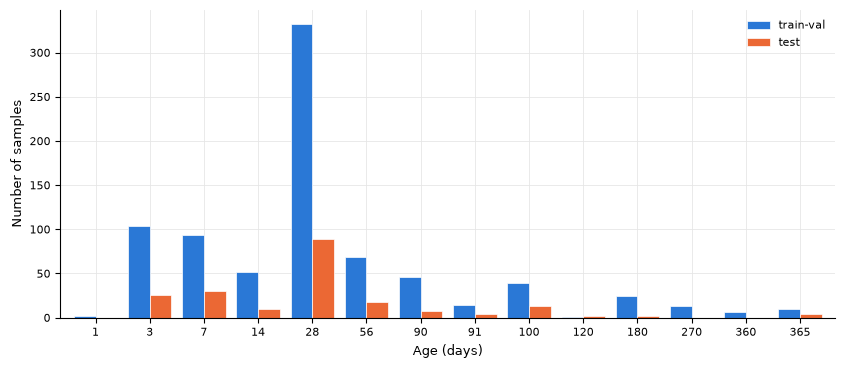

**Figura 1.** Número de muestras en cada edad del concreto, en train-val y en prueba.

Distinct ages in train-val: 14
Test ages not present in train-val: none


In [8]:
# The age only takes a few discrete values: count the samples at each age
age_counts = (pd.DataFrame({"train-val": train_val_df["age"].value_counts(),
                            "test": test_df["age"].value_counts()})
              .fillna(0).astype(int).sort_index())

ax = age_counts.plot.bar(figsize=(10, 4), color=[COLOR_TRAIN, COLOR_TEST],
                         width=0.8, edgecolor="white", linewidth=0.5)
ax.set_xlabel(LABELS["age"])
ax.set_ylabel("Number of samples")
ax.tick_params(axis="x", rotation=0)
show_figure(ax.figure, 1, "Número de muestras en cada edad del concreto, en train-val y en prueba.")

print(f"Distinct ages in train-val: {train_val_df['age'].nunique()}")
print(f"Test ages not present in train-val: "
      f"{sorted(set(test_df['age']) - set(train_val_df['age'])) or 'none'}")

Observaciones de la Figura 1:

- La edad solo toma **14 valores distintos**, que corresponden a las edades de ensayo habituales en laboratorio (3, 7, 14, 28, 56, 90 días, etc.). Por eso puede tratarse como una variable numérica o como una variable categórica (one-hot), alternativa que se compara en la sección 8.2.
- La edad de **28 días**, que es la edad de referencia para especificar la resistencia del concreto, concentra cerca del 40 % de las muestras. Algunas edades tienen muy pocas muestras (1 día: 2 muestras; 120 días: 1 muestra).
- Todas las edades del conjunto de prueba aparecen en train-val, así que una codificación one-hot no encontraría categorías desconocidas al evaluar en prueba.

**Cobertura del conjunto de prueba: mezclas que también aparecen en train-val.** Para esta revisión solo se comparan las variables de entrada (mezcla y edad), sin mirar la resistencia del conjunto de prueba.

In [9]:
# Test samples whose inputs (mix and age) also appear in train-val
train_val_mixes = train_val_df[FEATURES].drop_duplicates()
test_seen_mix = (test_df[FEATURES]
                 .merge(train_val_mixes, how="left", indicator=True)["_merge"]
                 .eq("both")
                 .to_numpy())

print(f"Test samples with repeated inputs within test: {test_df.duplicated(subset=FEATURES).sum()}")
print(f"Test samples whose mix and age also appear in train-val: "
      f"{test_seen_mix.sum()} of {len(test_df)} ({test_seen_mix.mean():.1%})")

Test samples with repeated inputs within test: 1
Test samples whose mix and age also appear in train-val: 10 of 206 (4.9%)


El conjunto de prueba **no se modifica**: es el conjunto de referencia entregado con el enunciado para la evaluación final. La máscara `test_seen_mix` se guarda para reportar en la sección 9 el desempeño en prueba también sin estas muestras, y así comprobar que el resultado no está inflado porque el modelo ya conocía esas mezclas.

### 2.3 Detección de posibles outliers

Un outlier es un registro cuya resistencia medida se aparta mucho de lo que indican los demás registros con mezclas y edades parecidas, por ejemplo por un error de registro o un ensayo defectuoso. Para encontrarlos se entrena una red neuronal con el resto de los datos y se compara su predicción con la resistencia medida de cada registro. En esta sección solo se **identifican** los registros que se salen de lo normal; la regla para marcarlos y la decisión de conservarlos o descartarlos se toman después de analizarlos por separado.

La predicción de cada registro tiene que hacerla un modelo que **no lo vio** durante el entrenamiento; si no, la red podría memorizarlo y su error saldría bajo aunque el dato fuera raro. Para eso se usa la validación cruzada k-fold con $K = 10$: los 805 registros se reparten al azar en 10 folds de 80 u 81 registros, se entrena la red 10 veces con 9 folds (724 o 725 registros) y en cada vuelta se predice el fold que quedó fuera. Al final, cada registro tiene una **predicción fuera del fold**.

Detalles de esta revisión:

- **Datos:** train-val sin duplicados (805 registros), con las 8 variables de entrada originales, escaladas con `StandardScaler` dentro de cada fold.
- **Dos redes de diagnóstico**, para que el resultado no dependa de una sola arquitectura:
  - (a) 1 capa oculta de 8 neuronas, la arquitectura de Yeh (1998), con tasa de aprendizaje de 0.01;
  - (b) 2 capas ocultas de 64 y 32 neuronas, con más capacidad, con tasa de aprendizaje de 0.001.

  Ambas usan activación ReLU y el optimizador Adam. No son el modelo del trabajo (sección 6): solo se usan en esta revisión y no se ajustan sus hiperparámetros.
- **5 repeticiones** de la validación cruzada, con las semillas 42 a 46. En cada repetición cambian los registros que forman cada fold y los pesos iniciales de la red, así que cada registro recibe 5 predicciones de 5 modelos distintos que no lo vieron. Así, el resultado no depende de un reparto o de una inicialización en particular.

La red se entrena minimizando el error cuadrático. Para las predicciones fuera del fold, el error cuadrático medio se calcula con la Ecuación (1):

$$
J = \frac{1}{m}\sum_{i=1}^{m}\left(\hat{y}_i - y_i\right)^2 \tag{1}
$$

donde $m = 805$ es el número de registros, $y_i$ es la resistencia medida del registro $i$ y $\hat{y}_i$ es su predicción fuera del fold. Cada registro aporta el término $(\hat{y}_i - y_i)^2/m$, así que los registros que la red predice peor son los que más aportan a $J$. La raíz cuadrada de $J$ es el RMSE, en MPa.

In [10]:
# Diagnostic networks: used only to look for unusual records, without tuning
DIAGNOSTIC_NETWORKS = {
    "(a) 1 hidden layer, 8 units": dict(hidden_layer_sizes=(8,), learning_rate_init=0.01,
                                        max_iter=5000),
    "(b) 2 hidden layers, 64 and 32 units": dict(hidden_layer_sizes=(64, 32), learning_rate_init=0.001,
                                                 max_iter=3000),
}
REPEAT_SEEDS = [SEED + r for r in range(5)]   # 42 to 46: new folds and new initial weights each time

X_diag = train_val_df[FEATURES]
y_diag = train_val_df[TARGET]

# Out-of-fold predictions: one row per record, one column per repetition
oof_predictions = {}
for name, params in DIAGNOSTIC_NETWORKS.items():
    predictions = pd.DataFrame(index=y_diag.index, columns=REPEAT_SEEDS, dtype=float)
    for seed in REPEAT_SEEDS:
        model = make_pipeline(StandardScaler(), MLPRegressor(random_state=seed, **params))
        folds = KFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
        predictions[seed] = cross_val_predict(model, X_diag, y_diag, cv=folds, n_jobs=-1)
    oof_predictions[name] = predictions

# RMSE of the out-of-fold predictions (square root of Equation 1), for each repetition
oof_rmse = pd.DataFrame({name: np.sqrt(predictions.sub(y_diag, axis=0).pow(2).mean())
                         for name, predictions in oof_predictions.items()}).T
oof_rmse.columns = [f"seed {seed}" for seed in REPEAT_SEEDS]
oof_rmse["mean"] = oof_rmse.mean(axis=1)
show_table(oof_rmse, 7,
           "RMSE (MPa) de las predicciones fuera del fold de cada red de diagnóstico, en cada "
           "repetición de la validación cruzada.")

**Tabla 7.** RMSE (MPa) de las predicciones fuera del fold de cada red de diagnóstico, en cada repetición de la validación cruzada.

,seed 42,seed 43,seed 44,seed 45,seed 46,mean
"(a) 1 hidden layer, 8 units",6.43,8.91,10.27,6.96,6.41,7.80
"(b) 2 hidden layers, 64 and 32 units",5.34,5.50,5.17,5.34,5.38,5.35


> **Hallazgo para analizar más adelante (secciones 7 y 8.5).** Al preparar esta revisión se probaron varias configuraciones de la red de 1 capa con 8 neuronas, con las mismas 5 repeticiones de la validación cruzada:
>
> - Con ReLU y la tasa de aprendizaje por defecto (0.001), la red **no alcanzó a converger** en 43 de los 50 entrenamientos, aun con 3000 iteraciones.
> - Con ReLU y una tasa de 0.01 (la configuración usada aquí), sí converge, pero el RMSE **cambia mucho de una repetición a otra** (en la prueba preliminar, entre 6.4 y 10.3 MPa; ver la fila (a) de la Tabla 7). La causa probable es que, con tan pocas neuronas, algunas "mueren": una neurona ReLU cuya entrada queda negativa para todos los registros siempre devuelve cero y deja de aprender. Si esto pasa en un fold, la red de ese fold queda con menos capacidad y predice peor.
> - Con la activación tanh y una tasa de 0.01, la misma red converge en los 50 entrenamientos y el RMSE es estable (entre 5.9 y 6.1 MPa en la prueba preliminar).
>
> Esto sugiere que, en redes pequeñas, la función de activación y la tasa de aprendizaje influyen mucho en la estabilidad del entrenamiento. Se analizará con detalle al diagnosticar el modelo (sección 7) y al comparar funciones de activación (sección 8.5). Para esta revisión implica que algunos errores altos de la red (a) pueden deberse a una mala repetición de la red y no al registro; por eso la Figura 2 muestra también el rango de las 5 repeticiones.

Para comparar la predicción con la medición de cada registro se usa el cociente entre ambas (Ecuación 2), promediado en las 5 repeticiones:

$$
\bar{q}_i = \frac{1}{R}\sum_{r=1}^{R}\frac{\hat{y}_i^{(r)}}{y_i} \tag{2}
$$

donde $R = 5$ es el número de repeticiones y $\hat{y}_i^{(r)}$ es la predicción fuera del fold del registro $i$ en la repetición $r$. Un cociente $\bar{q}_i = 1$ es una predicción perfecta; $\bar{q}_i > 1$ indica que la red predice más resistencia de la medida, y $\bar{q}_i < 1$, menos. Es un error **relativo**: el mismo error en MPa da un cociente más alejado de 1 en un registro de baja resistencia (por ejemplo, 5 MPa de más da 1.50 en un registro de 10 MPa y 1.08 en uno de 60 MPa).

En la Figura 2 los registros están en el orden del archivo `train-val.csv`, el mismo en los dos paneles, de modo que cada posición horizontal corresponde al mismo registro en ambas redes. El eje vertical está en **escala logarítmica**: el cociente no puede bajar de 0 pero no tiene límite hacia arriba, así que en escala lineal una sobreestimación al doble (2) se vería más lejos de 1 que una subestimación a la mitad (0.5). En escala logarítmica ambas quedan a la misma distancia de 1, una por encima y otra por debajo. Los resultados se grafican tal como salen de las redes, sin ningún ajuste.

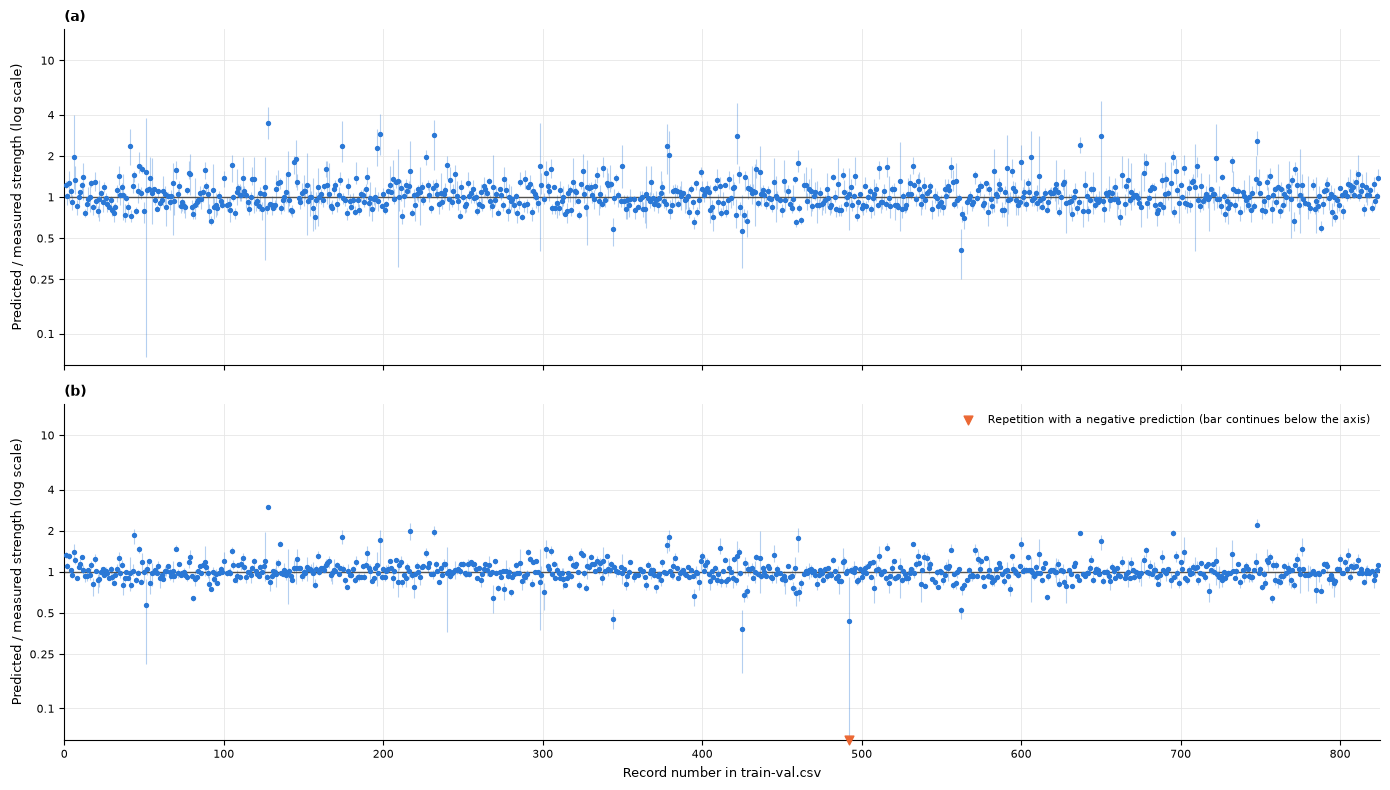

**Figura 2.** Cociente entre la resistencia predicha fuera del fold y la medida, para cada registro de train-val en el orden del archivo, con el eje vertical en escala logarítmica: (a) red de 1 capa oculta con 8 neuronas; (b) red de 2 capas ocultas con 64 y 32 neuronas. El punto es el promedio de las 5 repeticiones (Ecuación 2) y la barra vertical va del mínimo al máximo. La línea gris marca la predicción perfecta (cociente = 1). El triángulo naranja señala un registro con una predicción negativa en alguna repetición, que no puede representarse en escala logarítmica.

In [11]:
# Predicted / measured ratio of every record in every repetition
oof_ratios = {name: predictions.div(y_diag, axis=0) for name, predictions in oof_predictions.items()}

# Logarithmic axis, symmetric around 1 so that a ratio q and its inverse 1/q are equally far from 1
positive_ratios = pd.concat(oof_ratios.values(), axis=1).to_numpy()
positive_ratios = positive_ratios[positive_ratios > 0]
y_limit = 1.15 * np.exp(np.abs(np.log(positive_ratios)).max())
RATIO_TICKS = [0.1, 0.25, 0.5, 1, 2, 4, 10]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, sharey=True)
for ax, panel, ratio in zip(axes, ["(a)", "(b)"], oof_ratios.values()):
    # Vertical bar: range of the 5 repetitions; dot: mean ratio (Equation 2).
    # A negative prediction cannot be drawn on a log axis: its bar goes down to the bottom edge.
    lower = ratio.min(axis=1).where(ratio.min(axis=1) > 0, 1 / y_limit)
    ax.vlines(ratio.index, lower, ratio.max(axis=1), color=COLOR_TRAIN, alpha=0.35, linewidth=0.8)
    ax.scatter(ratio.index, ratio.mean(axis=1), s=8, color=COLOR_TRAIN, zorder=3)
    negative = ratio.index[ratio.min(axis=1) <= 0]
    if len(negative) > 0:
        ax.scatter(negative, np.full(len(negative), 1 / y_limit), marker="v", s=40,
                   color=COLOR_TEST, zorder=4, clip_on=False,
                   label="Repetition with a negative prediction (bar continues below the axis)")
        ax.legend(loc="upper right")
    ax.axhline(1, color=COLOR_MUTED, linewidth=1)
    ax.set_yscale("log")
    ax.set_ylim(1 / y_limit, y_limit)
    ax.set_yticks([t for t in RATIO_TICKS if 1 / y_limit <= t <= y_limit])
    ax.set_yticklabels([f"{t:g}" for t in RATIO_TICKS if 1 / y_limit <= t <= y_limit])
    ax.minorticks_off()
    ax.set_ylabel("Predicted / measured strength (log scale)")
    ax.set_title(panel, loc="left", fontweight="bold")
axes[-1].set_xlabel("Record number in train-val.csv")
axes[-1].set_xlim(0, train_val_df.index.max() + 1)
fig.tight_layout()
show_figure(fig, 2,
            "Cociente entre la resistencia predicha fuera del fold y la medida, para cada registro de "
            "train-val en el orden del archivo, con el eje vertical en escala logarítmica: (a) red de 1 "
            "capa oculta con 8 neuronas; (b) red de 2 capas ocultas con 64 y 32 neuronas. El punto es el "
            "promedio de las 5 repeticiones (Ecuación 2) y la barra vertical va del mínimo al máximo. La "
            "línea gris marca la predicción perfecta (cociente = 1). El triángulo naranja señala un "
            "registro con una predicción negativa en alguna repetición, que no puede representarse en "
            "escala logarítmica.")

Observaciones de la Figura 2:

- **La red (b) es más consistente que la (a).** En la red (b), el 90 % central de los cocientes promedio está entre 0.80 y 1.31, y la mediana del rango entre repeticiones es 0.11; en la red (a), esos valores son 0.78 a 1.59 y 0.24. Las barras más largas de la red (a) reflejan la inestabilidad descrita en el hallazgo anterior: varios de sus puntos alejados de 1 se deben a repeticiones malas de la red y no al registro.
- **Los registros que más se apartan son, sobre todo, de baja resistencia y edades tempranas** (1, 3 y 7 días, con menos de unos 15 MPa). En parte es un efecto del cociente, que mide el error relativo: un error de pocos MPa en un registro de 5 MPa da un cociente de 2 o más.
- **Algunos registros se apartan en las dos redes y con barras cortas**, es decir, de forma consistente:
  - **Registros 128 y 748** (cocientes de 3.0 y 2.2 en la red b): son los dos únicos registros ensayados a 1 día. La red sobreestima su resistencia porque casi no tiene ejemplos de esa edad; pueden ser datos correctos pero poco representados.
  - **Registros 81 y 695:** son el par de la Tabla 5 con 33 MPa de diferencia (55.9 y 22.9 MPa, la misma mezcla a 7 días). La red predice un valor intermedio, así que uno queda por debajo de 1 (0.64) y el otro por encima (1.91). El registro 616 (52.0 MPa), de otro grupo de la Tabla 5 (446 kg/m³ de cemento a 7 días), muestra lo mismo en menor grado.
  - **Registros 425, 344 y 562:** las dos redes predicen mucho menos de lo medido (cocientes de 0.38 a 0.59). Su resistencia medida es mayor de lo que indican las mezclas parecidas.

**Error relativo absoluto.** Otra forma de comparar todos los registros por igual es el error relativo absoluto: la diferencia entre la resistencia medida y la predicha, en valor absoluto, dividida entre la resistencia medida (Ecuación 3). Para cada registro se promedia en las 5 repeticiones:

$$
\bar{\varepsilon}_i = \frac{1}{R}\sum_{r=1}^{R}\frac{\left|y_i - \hat{y}_i^{(r)}\right|}{y_i} \tag{3}
$$

donde $y_i$ es la resistencia medida del registro $i$, $\hat{y}_i^{(r)}$ es su predicción fuera del fold en la repetición $r$ y $R = 5$. Un valor $\bar{\varepsilon}_i = 0.2$ significa que, en promedio, la red se equivoca en un 20 % de la resistencia medida de ese registro. A diferencia del cociente de la Figura 2, no distingue si la red predice de más o de menos: una sobreestimación y una subestimación de la misma cantidad de MPa dan el mismo error. La Figura 3 lo muestra para cada registro, en el mismo orden que la Figura 2.

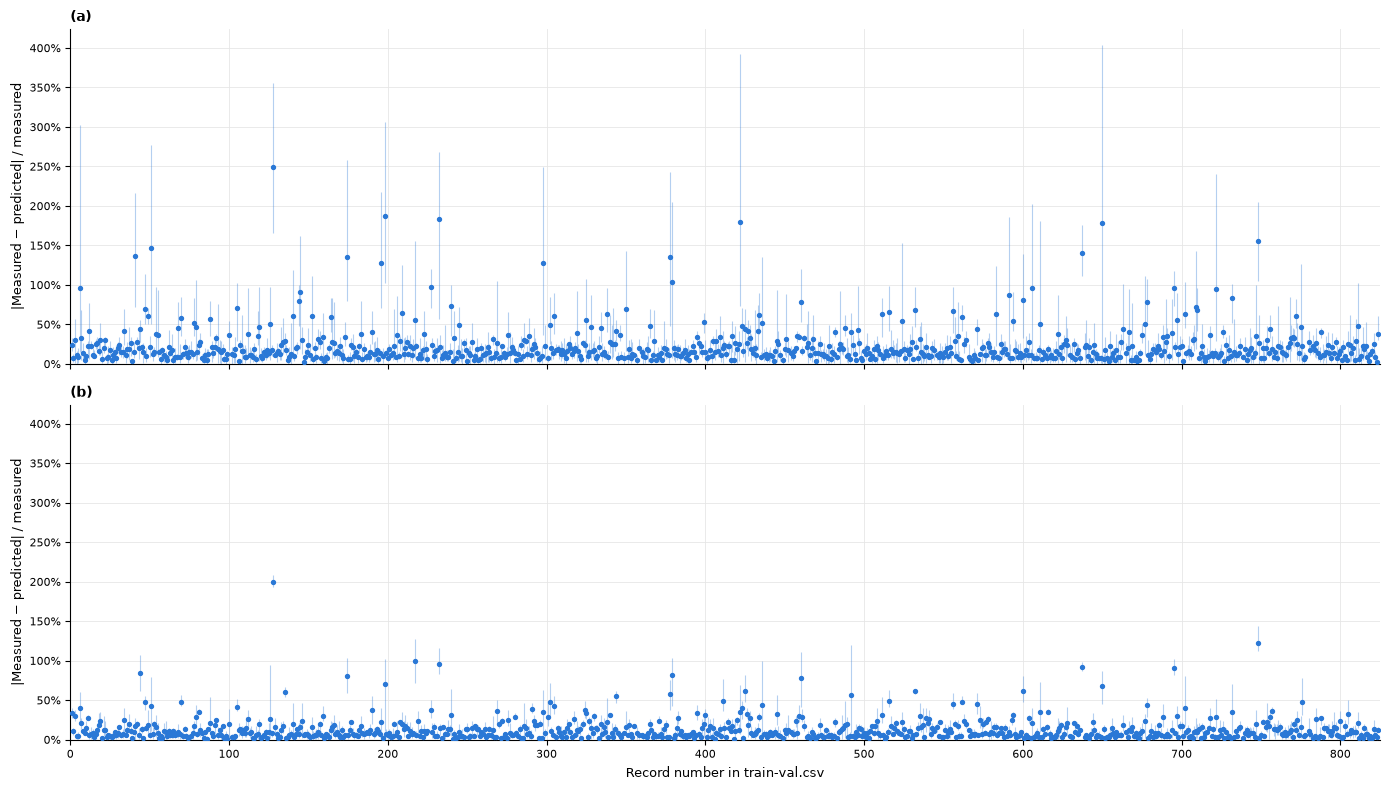

**Figura 3.** Error relativo absoluto de la predicción fuera del fold, para cada registro de train-val en el orden del archivo: (a) red de 1 capa oculta con 8 neuronas; (b) red de 2 capas ocultas con 64 y 32 neuronas. El punto es el promedio de las 5 repeticiones (Ecuación 3) y la barra vertical va del mínimo al máximo.

In [12]:
# Absolute relative error of every record in every repetition (Equation 3)
oof_rel_errors = {name: predictions.sub(y_diag, axis=0).abs().div(y_diag, axis=0)
                  for name, predictions in oof_predictions.items()}

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, sharey=True)
for ax, panel, error in zip(axes, ["(a)", "(b)"], oof_rel_errors.values()):
    # Vertical bar: range of the 5 repetitions; dot: mean error (Equation 3)
    ax.vlines(error.index, error.min(axis=1), error.max(axis=1),
              color=COLOR_TRAIN, alpha=0.35, linewidth=0.8)
    ax.scatter(error.index, error.mean(axis=1), s=8, color=COLOR_TRAIN, zorder=3)
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_ylabel("|Measured − predicted| / measured")
    ax.set_title(panel, loc="left", fontweight="bold")
axes[-1].set_xlabel("Record number in train-val.csv")
axes[-1].set_xlim(0, train_val_df.index.max() + 1)
fig.tight_layout()
show_figure(fig, 3,
            "Error relativo absoluto de la predicción fuera del fold, para cada registro de train-val "
            "en el orden del archivo: (a) red de 1 capa oculta con 8 neuronas; (b) red de 2 capas "
            "ocultas con 64 y 32 neuronas. El punto es el promedio de las 5 repeticiones "
            "(Ecuación 3) y la barra vertical va del mínimo al máximo.")

**Distribución del error relativo.** Para ver la distribución de los errores se usa el error relativo **con signo**, es decir, sin valor absoluto (Ecuación 4), promediado en las 5 repeticiones:

$$
\bar{e}_i = \frac{1}{R}\sum_{r=1}^{R}\frac{y_i - \hat{y}_i^{(r)}}{y_i} \tag{4}
$$

Un valor $\bar{e}_i > 0$ indica que la red predice **menos** resistencia de la medida (subestima), y $\bar{e}_i < 0$, que predice **más** (sobreestima). Como las predicciones casi nunca son negativas, la subestimación no puede pasar de 100 % ($\hat{y} = 0$), mientras que la sobreestimación no tiene límite. La Tabla 8 y la Figura 4 resumen la distribución de este error para los 805 registros, en cada red.

Para juzgar si los errores siguen una distribución normal, sobre cada histograma se dibuja la densidad normal con la media $\mu$ y la desviación estándar $\sigma$ de los errores de esa red (Ecuación 5):

$$
f(e) = \frac{1}{\sigma\sqrt{2\pi}}\exp\left[-\frac{1}{2}\left(\frac{e - \mu}{\sigma}\right)^2\right] \tag{5}
$$

donde $e$ es el error relativo con signo. Para compararla con el histograma, que cuenta registros, la densidad se multiplica por el número de registros (805) y por el ancho de los intervalos (2.5 %).

**Tabla 8.** Estadísticas del error relativo con signo promedio de los registros de train-val (%), para cada red de diagnóstico.

,mean,std,min,1%,2.5%,25%,50%,75%,97.5%,99%,max
"(a) 1 hidden layer, 8 units",-7.5,29.6,-249.1,-135.7,-80.0,-17.3,-1.6,10.7,26.4,32.6,59.0
"(b) 2 hidden layers, 64 and 32 units",-2.6,19.3,-199.8,-80.1,-47.2,-8.4,0.2,7.0,24.7,34.6,62.1


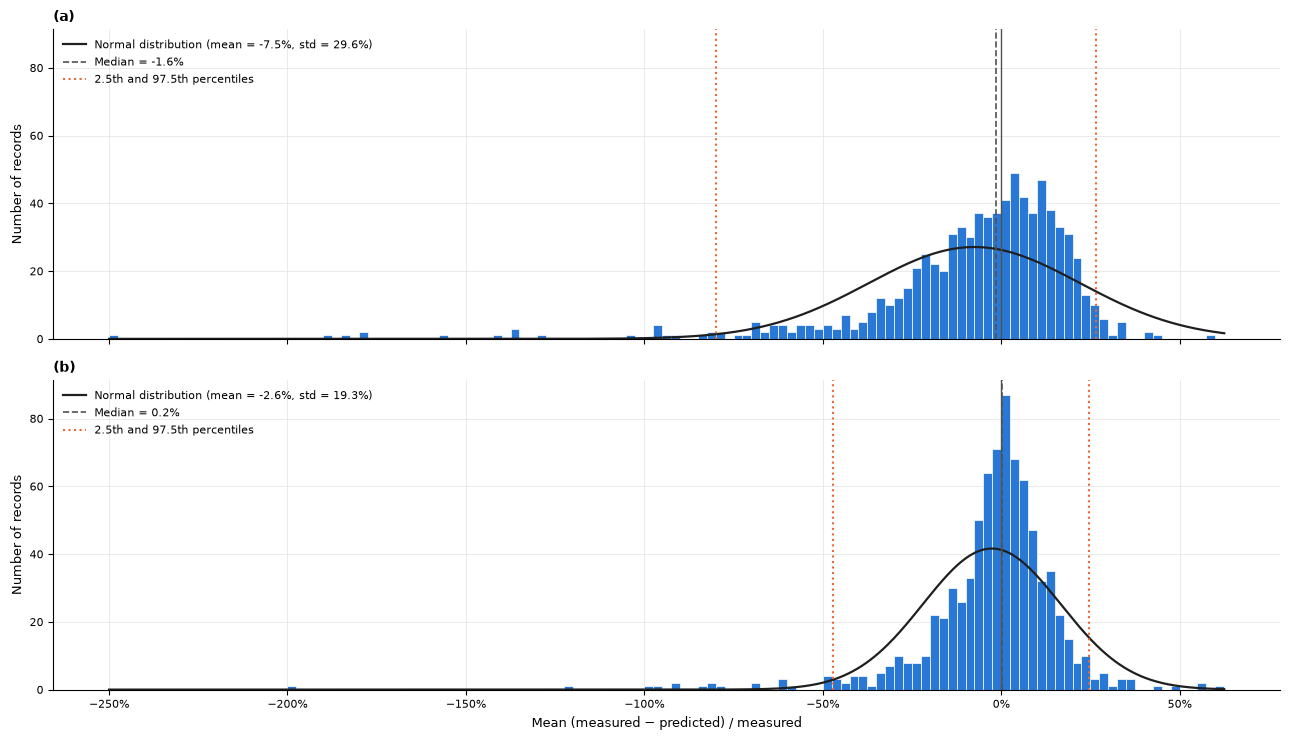

**Figura 4.** Histograma del error relativo con signo promedio de los registros de train-val (Ecuación 4, intervalos de 2.5 %): (a) red de 1 capa oculta con 8 neuronas; (b) red de 2 capas ocultas con 64 y 32 neuronas. Valores positivos: la red subestima; negativos: sobreestima. La curva negra es la distribución normal con la media y la desviación estándar de los errores (Ecuación 5). La línea gris continua marca el cero, la discontinua la mediana y las punteadas los percentiles 2.5 y 97.5.

In [13]:
# Mean signed relative error of each record (Equation 4): > 0 underestimates, < 0 overestimates
mean_signed_errors = pd.DataFrame({name: (-predictions).add(y_diag, axis=0).div(y_diag, axis=0).mean(axis=1)
                                   for name, predictions in oof_predictions.items()})

error_summary = mean_signed_errors.describe(percentiles=[0.01, 0.025, 0.25, 0.5, 0.75, 0.975, 0.99]).T
error_summary = error_summary.drop(columns=["count"])
show_table(error_summary * 100, 8,
           "Estadísticas del error relativo con signo promedio de los registros de train-val (%), "
           "para cada red de diagnóstico.", precision=1)

bin_width = 0.025
bins = np.arange(np.floor(mean_signed_errors.to_numpy().min() / bin_width) * bin_width,
                 mean_signed_errors.to_numpy().max() + bin_width, bin_width)
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True, sharey=True)
for ax, panel, (name, error) in zip(axes, ["(a)", "(b)"], mean_signed_errors.items()):
    ax.hist(error, bins=bins, color=COLOR_TRAIN, edgecolor="white", linewidth=0.5)
    # Normal distribution with the mean and standard deviation of the errors (Equation 5),
    # scaled to counts: number of records x bin width x probability density
    mu, sigma = error.mean(), error.std()
    x = np.linspace(bins[0], bins[-1], 1000)
    normal_pdf = np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))
    ax.plot(x, len(error) * bin_width * normal_pdf, color="#1f1f1f", linewidth=1.6,
            label=f"Normal distribution (mean = {mu:.1%}, std = {sigma:.1%})")
    ax.axvline(0, color=COLOR_MUTED, linewidth=1)
    ax.axvline(error.median(), color=COLOR_MUTED, linestyle="--", linewidth=1.2,
               label=f"Median = {error.median():.1%}")
    for q in (0.025, 0.975):
        ax.axvline(error.quantile(q), color=COLOR_TEST, linestyle=":", linewidth=1.5,
                   label="2.5th and 97.5th percentiles" if q == 0.025 else None)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_ylabel("Number of records")
    ax.set_title(panel, loc="left", fontweight="bold")
    ax.legend(loc="upper left")
axes[-1].set_xlabel("Mean (measured − predicted) / measured")
fig.tight_layout()
show_figure(fig, 4,
            "Histograma del error relativo con signo promedio de los registros de train-val (Ecuación 4, "
            "intervalos de 2.5 %): (a) red de 1 capa oculta con 8 neuronas; (b) red de 2 capas ocultas "
            "con 64 y 32 neuronas. Valores positivos: la red subestima; negativos: sobreestima. La curva "
            "negra es la distribución normal con la media y la desviación estándar de los errores "
            "(Ecuación 5). La línea gris continua marca el cero, la discontinua la mediana y las "
            "punteadas los percentiles 2.5 y 97.5.")

Observaciones de las Figuras 3 y 4:

Figura 3 (error relativo absoluto):

- En la red (b), la mayoría de los registros tienen errores menores de 25 %, y solo 19 superan el 50 %; en la red (a) son 61. De los 19 de la red (b), 14 también superan el 50 % en la red (a).
- Solo dos registros superan el 100 % en la red (b): el 128 (200 %) y el 748 (122 %), los dos únicos ensayados a 1 día.
- Los 19 registros con más de 50 % en la red (b) tienen una resistencia mediana de 10.7 MPa (frente a 33.8 MPa de todo train-val), 14 de ellos son de 1, 3 o 7 días, y en 16 la red sobreestima la resistencia. En general, los registros de menos de 10 MPa (32 en total) tienen un error mediano de 32 %, frente a 8 % en los demás: con una resistencia medida pequeña, unos pocos MPa de error dan un porcentaje grande.

Figura 4 y Tabla 8 (error relativo con signo):

- En la red (b), la distribución está centrada en cero (mediana de 0.2 %) y la mitad central de los registros está entre −8.4 % y 7.0 %. En la red (a) es más ancha y está algo desplazada hacia la sobreestimación (mediana de −1.6 %).
- La parte central tiene forma de campana, pero la distribución **no es simétrica**: tiene una cola larga hacia la izquierda (sobreestimación), que llega a −200 % en la red (b), mientras que hacia la derecha (subestimación) no pasa de 62 %. En la red (b), el 95 % central de los registros está entre −47.2 % y 24.7 %. Esta asimetría se debe en parte a la definición del error: subestimar no puede dar más de 100 %, pero sobreestimar no tiene límite, y los registros de baja resistencia amplifican el porcentaje.
- **Comparación con la distribución normal.** Los errores no siguen bien la distribución normal con su misma media y desviación estándar. En la red (b), el histograma es mucho más alto y estrecho que la curva normal cerca de cero, queda por debajo de ella en los costados (entre unos 15 % y 35 % hacia ambos lados) y tiene más registros que ella en la cola izquierda, más allá de −50 %. Es decir, la distribución real es más **puntiaguda y de colas más pesadas** que la normal, y además asimétrica. Esto ocurre porque unos pocos registros muy mal predichos desplazan la media hacia la izquierda (−2.6 %, frente a una mediana de 0.2 %) e inflan la desviación estándar (19.3 %). Si los errores fueran normales, la mitad central de los registros (entre −8.4 % y 7.0 %) correspondería a una desviación estándar de solo unos 11 %.
- Por lo mismo, una regla del tipo "media ± k desviaciones estándar" quedaría distorsionada por los mismos registros que se quieren detectar. Una regla basada en la mediana y los percentiles, que no se ven afectados por los valores extremos, sería más confiable.
- Los registros de la cola izquierda son los candidatos a outlier más claros: son registros cuya resistencia medida es mucho más baja de lo que indican las mezclas parecidas.

**Regla pendiente.** La regla para marcar un registro como posible outlier se define a partir de las Figuras 2 a 4. Después, los candidatos se analizarán uno por uno antes de decidir si se conservan o se descartan.

### 2.4 Relación entre variables

Todas las figuras de esta sección usan el conjunto train-val sin duplicados (805 registros).

**Correlación entre variables**

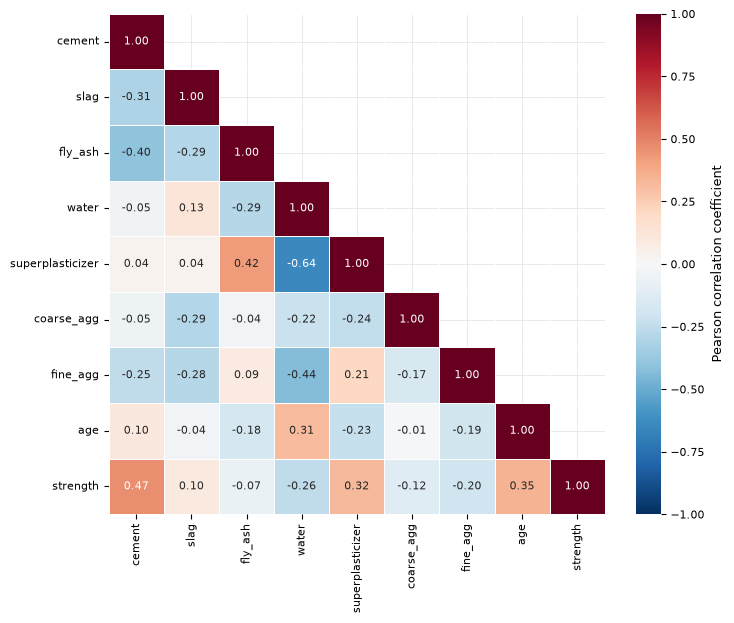

**Figura 5.** Coeficientes de correlación de Pearson entre las variables de train-val.

In [14]:
correlation = train_val_df.corr(method="pearson")
upper_triangle = np.triu(np.ones_like(correlation, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(correlation, mask=upper_triangle, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Pearson correlation coefficient"}, ax=ax)
show_figure(fig, 5, "Coeficientes de correlación de Pearson entre las variables de train-val.")

Los valores de la Figura 5 son coeficientes de correlación de Pearson. Para dos variables $x$ y $y$ se calculan con la Ecuación (6):

$$
r_{xy} = \frac{\sum_{i=1}^{m}(x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{m}(x_i - \bar{x})^2}\,\sqrt{\sum_{i=1}^{m}(y_i - \bar{y})^2}} \tag{6}
$$

donde $m$ es el número de muestras, $x_i$ y $y_i$ son los valores de la muestra $i$, y $\bar{x}$ y $\bar{y}$ son las medias. Toma valores entre $-1$ y $1$ y **solo mide relaciones lineales**.

Observaciones de la Figura 5:

- Ninguna variable explica por sí sola la resistencia. Las correlaciones más altas con la resistencia son las del cemento ($r = 0.47$), la edad ($0.35$) y el superplastificante ($0.32$), y la del agua es negativa ($-0.26$). Las demás son débiles.
- Que las correlaciones lineales sean moderadas no significa que las variables no influyan: la resistencia depende de **combinaciones** de componentes (por ejemplo, la relación agua/cemento) y de relaciones no lineales, como la de la edad. Esto justifica usar un modelo no lineal como una red neuronal.
- La correlación más fuerte entre entradas es la del agua con el superplastificante ($-0.64$): el superplastificante se usa justamente para reducir el agua necesaria sin perder trabajabilidad. Ninguna otra pareja de entradas tiene una correlación tan alta como para considerarla redundante.

**Resistencia vs. edad**

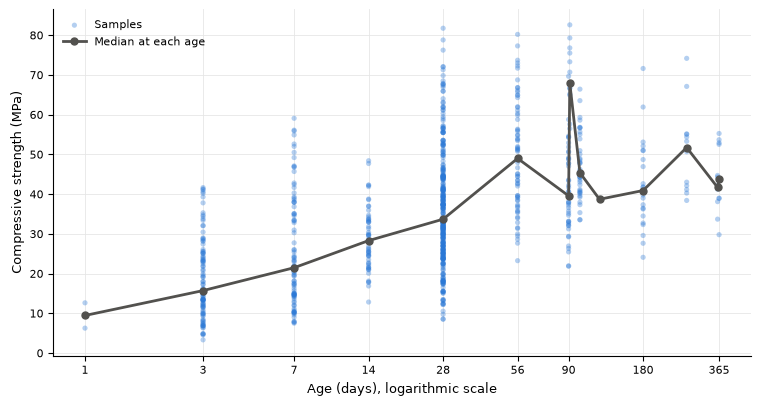

**Figura 6.** Resistencia a compresión vs. edad en train-val, con el eje horizontal en escala logarítmica. La línea gris une las medianas de cada edad.

Pearson r between strength and age:     0.35
Pearson r between strength and ln(age): 0.56


In [15]:
median_by_age = train_val_df.groupby("age")[TARGET].median()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(train_val_df["age"], train_val_df[TARGET], s=14, alpha=0.35,
           color=COLOR_TRAIN, edgecolors="none", label="Samples")
ax.plot(median_by_age.index, median_by_age.values, color=COLOR_MUTED, linewidth=2,
        marker="o", markersize=5, label="Median at each age")
ax.set_xscale("log")
# Label only a subset of ages so that close values (90/91/100, 360/365) do not overlap
AGE_TICKS = [1, 3, 7, 14, 28, 56, 90, 180, 365]
ax.set_xticks(AGE_TICKS)
ax.set_xticklabels(AGE_TICKS)
ax.minorticks_off()
ax.set_xlabel(LABELS["age"] + ", logarithmic scale")
ax.set_ylabel(LABELS[TARGET])
ax.legend(loc="upper left")
show_figure(fig, 6,
            "Resistencia a compresión vs. edad en train-val, con el eje horizontal en escala logarítmica. "
            "La línea gris une las medianas de cada edad.")

r_age = train_val_df["age"].corr(train_val_df[TARGET])
r_log_age = np.log(train_val_df["age"]).corr(train_val_df[TARGET])
print(f"Pearson r between strength and age:     {r_age:.2f}")
print(f"Pearson r between strength and ln(age): {r_log_age:.2f}")

Observaciones de la Figura 6:

- La resistencia crece rápido durante los primeros 28 días y después crece cada vez más lento, que es el comportamiento conocido del curado del concreto.
- En escala logarítmica la tendencia se parece más a una recta: la correlación con $\ln(\text{edad})$ ($r = 0.56$) es mayor que con la edad en días ($r = 0.35$). Esto coincide con la fórmula de regresión de Yeh (1998), que usa el término $\ln(t)$, y sugiere transformar la edad antes de entrenar la red (sección 8.2).
- Después de los 56 días la mediana sube y baja (por ejemplo, 67.9 MPa a los 91 días y 45.4 MPa a los 100 días). Esto no significa que el concreto pierda resistencia: cada edad incluye mezclas distintas, así que estas diferencias se deben a la dosificación y no a la edad.
- Para una misma edad la dispersión es grande (a los 28 días hay resistencias de menos de 10 MPa y de más de 80 MPa), lo que confirma que la edad por sí sola no basta para predecir la resistencia.

**Resistencia vs. relaciones agua/cemento y agua/aglomerante**

La ley de Abrams establece que la resistencia del concreto disminuye cuando aumenta la relación agua/cemento. Yeh (1998) muestra que, en concretos con escoria y ceniza volante, la relación agua/aglomerante predice mejor la resistencia. Ambas relaciones se definen con las Ecuaciones (7) y (8):

$$
\frac{w}{c} = \frac{W}{C} \tag{7}
$$

$$
\frac{w}{b} = \frac{W}{B} = \frac{W}{C + S + F} \tag{8}
$$

donde $W$ es la masa de agua, $C$ la de cemento, $S$ la de escoria de alto horno y $F$ la de ceniza volante, todas en kg por m³ de mezcla, y $B = C + S + F$ es la masa total de aglomerante. Aquí se calculan solo para graficarlas; su uso como variables de entrada se evalúa en la sección 8.1.

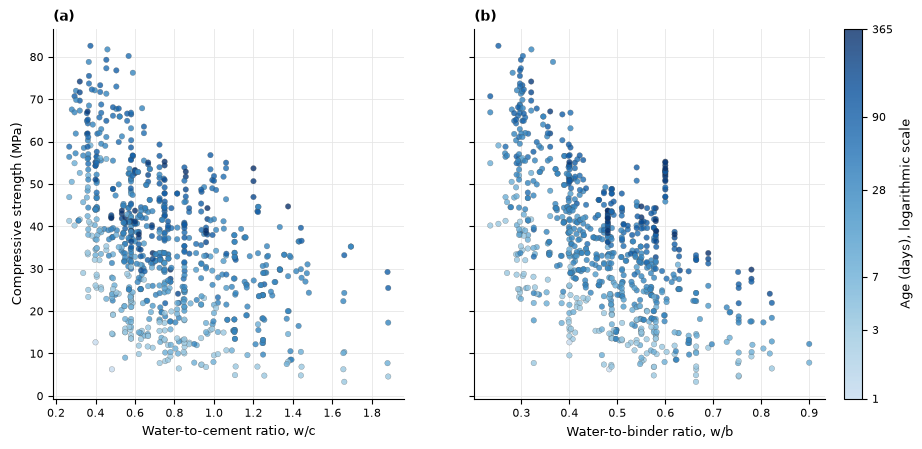

**Figura 7.** Resistencia a compresión vs. (a) relación agua/cemento y (b) relación agua/aglomerante, en train-val. El color indica la edad del concreto. Coeficiente de correlación de Pearson: (a) r = -0.47; (b) r = -0.59.

In [16]:
# Sequential blue scale without its near-white end, so that young samples stay visible
AGE_CMAP = ListedColormap(plt.get_cmap("Blues")(np.linspace(0.25, 1.0, 256)))

binder = train_val_df["cement"] + train_val_df["slag"] + train_val_df["fly_ash"]
ratios = {
    "Water-to-cement ratio, w/c": train_val_df["water"] / train_val_df["cement"],
    "Water-to-binder ratio, w/b": train_val_df["water"] / binder,
}

r_ratios = {name: ratio.corr(train_val_df[TARGET]) for name, ratio in ratios.items()}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, panel, (name, ratio) in zip(axes, ["(a)", "(b)"], ratios.items()):
    points = ax.scatter(ratio, train_val_df[TARGET], c=train_val_df["age"], cmap=AGE_CMAP,
                        norm=LogNorm(vmin=1, vmax=365), s=16, alpha=0.8,
                        edgecolors=COLOR_MUTED, linewidths=0.2)
    ax.set_xlabel(name)
    ax.set_title(panel, loc="left", fontweight="bold")
axes[0].set_ylabel(LABELS[TARGET])
colorbar = fig.colorbar(points, ax=axes, pad=0.02)
colorbar.set_ticks([1, 3, 7, 28, 90, 365])
colorbar.set_ticklabels(["1", "3", "7", "28", "90", "365"])
colorbar.minorticks_off()
colorbar.set_label(LABELS["age"] + ", logarithmic scale")
r_wc, r_wb = r_ratios.values()
show_figure(fig, 7,
            "Resistencia a compresión vs. (a) relación agua/cemento y (b) relación agua/aglomerante, "
            "en train-val. El color indica la edad del concreto. Coeficiente de correlación de Pearson: "
            f"(a) r = {r_wc:.2f}; (b) r = {r_wb:.2f}.")

Observaciones de la Figura 7:

- En ambas gráficas la resistencia disminuye cuando aumenta la relación, como predice la ley de Abrams.
- La relación agua/aglomerante tiene una correlación más fuerte con la resistencia ($r = -0.59$) que la relación agua/cemento ($r = -0.47$) y que cualquiera de las 8 variables originales (la mayor es la del cemento, $r = 0.47$). Esto coincide con lo que reporta Yeh (1998) y la convierte en una buena candidata como variable de entrada adicional (sección 8.1).
- Para una misma relación, buena parte de la dispersión vertical se explica por la edad: los puntos más oscuros (mayor edad) tienden a estar arriba. La red neuronal tendrá que combinar ambos efectos.

### 2.5 Observaciones del análisis exploratorio

> *Pendiente: conclusiones que guían el preprocesamiento y la ingeniería de variables.*

## 3. Métrica de evaluación

> *Pendiente: definición del RMSE (en LaTeX, con el significado de cada símbolo) y justificación de por qué es la métrica única para comparar modelos.*

## 4. Metodología de validación cruzada

> *Pendiente: explicación del k-fold, preprocesamiento dentro del `Pipeline` para evitar fuga de datos, función `evaluate` y tabla acumulada de experimentos, y criterio de diagnóstico de sesgo y varianza.*

## 5. Modelos de referencia

> *Pendiente: `DummyRegressor` (predice la media) y regresión lineal, como escala para juzgar los resultados de la red.*

## 6. Red neuronal base

> *Pendiente: arquitectura inicial (p. ej., 1 capa oculta de 8 neuronas, como Yeh), ecuaciones de propagación hacia adelante y función de costo, y resultado de validación cruzada.*

## 7. Diagnóstico de sesgo y varianza

### 7.1 Curva de aprendizaje

> *Pendiente: RMSE de entrenamiento y validación vs. número de muestras de entrenamiento.*

### 7.2 Curvas de validación

> *Pendiente: RMSE vs. número de neuronas y vs. parámetro de regularización $\alpha$.*

### 7.3 Curva de pérdida

> *Pendiente: evolución de la función de costo durante el entrenamiento para verificar la convergencia.*

### 7.4 Interpretación

> *Pendiente: diagnóstico del modelo base y estrategias a probar en la sección 8.*

## 8. Mejora del modelo

### 8.1 Nuevas variables de entrada

> *Pendiente: relaciones w/c, w/b, SP/b, escoria/b, ceniza/b y agregados/b.*

### 8.2 Tratamiento de la edad

> *Pendiente: edad cruda vs. $\ln(\text{edad})$ vs. one-hot de los 14 valores de edad.*

### 8.3 Escalado de entradas y salida

> *Pendiente: `StandardScaler` vs. `MinMaxScaler`, con y sin escalado de la resistencia.*

### 8.4 Arquitectura de la red

> *Pendiente: número de capas ocultas y de neuronas.*

### 8.5 Función de activación

> *Pendiente: `relu` vs. `tanh`.*

### 8.6 Optimizador y tasa de aprendizaje

> *Pendiente: `adam` vs. `sgd`, distintos valores de `learning_rate_init` y tasa adaptativa.*

### 8.7 Regularización

> *Pendiente: barrido de $\alpha$ (L2) y `early_stopping`.*

### 8.8 Búsqueda conjunta de hiperparámetros

> *Pendiente: `GridSearchCV` o `RandomizedSearchCV` con las mismas particiones k-fold.*

### 8.9 Resumen de experimentos

> *Pendiente: tabla de todos los experimentos ordenada por RMSE de validación cruzada y gráfica comparativa.*

## 9. Modelo final y evaluación en el conjunto de prueba

### 9.1 Entrenamiento del modelo final

> *Pendiente: reentrenamiento del mejor pipeline con todo train-val y su curva de aprendizaje.*

### 9.2 Desempeño en el conjunto de prueba

> *Pendiente: RMSE (y R², MAE como complemento) en prueba, comparado con el RMSE de validación cruzada; resultado también sin las filas repetidas entre train-val y test.*

### 9.3 Análisis de las predicciones

> *Pendiente: gráfico de paridad predicho vs. medido, residuos vs. predicción y vs. edad, y comparación con los resultados de Yeh (1998).*

## 10. Conclusiones

> *Pendiente: qué mejoró más el modelo, diagnóstico final de sesgo y varianza, limitaciones y trabajo futuro.*

## Referencias

- Yeh, I.C., 1998. Modeling of strength of high-performance concrete using artificial neural networks. *Cement and Concrete Research*, 28(12), pp. 1797-1808.